# Módulo 3 - Punto 3.2: Procesamiento en video y curva temporal fisiológica

**Objetivo.** Automatizar la segmentación de la pupila en todo el video, validar el área/diámetro automático contra la anotación manual, obtener la curva temporal D(t) y A(t), extraer los parámetros fisiológicos del reflejo fotomotor (latencia, amplitud, velocidades) y documentar cómo se detectan y tratan los artefactos.

Toda la lógica está en `src/modulo3/dinamica.py` (y la máscara de cada frame en `src/modulo3/descriptores.py`); los parámetros, en la sección `modulo3` de `config.yaml`. No se usa aprendizaje automático: segmentación clásica (Módulo 2), morfología, estadística robusta (mediana, MAD) y filtrado de señales 1D. Las figuras y tablas se guardan en `results/modulo3/`.

## 0. Configuración del entorno e importaciones

In [1]:
# --- Imports de la librería estándar ---
import sys
from pathlib import Path

# --- Configurar la raíz del repositorio ---
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros y propios ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from IPython.display import display

from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm
from src.modulo3 import descriptores as de
from src.modulo3 import dinamica as di      # funciones del punto 3.2

# --- Estilo de las figuras (el mismo del Módulo 4) ---
COLOR = {"crudo": "#a3a29b", "suave": "#0b0b0b", "rechazado": "#d0453a", "interp": "#2a78d6",
         "manual": "#ffffff", "auto": "#eda100", "watershed": "#2a78d6", "luz": "#f6e7b0"}
MOTIVO = {"forma": "Forma irregular", "salto_centroide": "Salto del centroide",
          "outlier": "Outlier (Hampel)", "sin_pupila": "Sin pupila (parpadeo)"}
COLOR_MOTIVO = {"forma": "#d0453a", "salto_centroide": "#8f4fd6", "outlier": "#eb6834", "sin_pupila": "#52514e"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "font.size": 10,
    "lines.linewidth": 2, "lines.markersize": 7,
})
pd.set_option("display.precision", 3)

def sombrear_luz(ax, est, t_fin):
    # Sombrea los intervalos con la luz encendida
    for t_on in est["encendido"]:
        apag = [t for t in est["apagado"] if t > t_on]
        ax.axvspan(t_on, apag[0] if apag else t_fin, color=COLOR["luz"], alpha=0.6, lw=0, zorder=0)

## 1. Procesamiento del video frame a frame

`di.procesar_registro` hace todo el recorrido. Para cada frame:

1. Recorta la ROI de `config.yaml` (la misma de todos los módulos).
2. Segmenta la pupila con `de.mascara_pupila`: pipeline del Módulo 2 (CLAHE + estimación del centro y radio + Watershed sobre el gradiente de Sobel) + la operación morfológica de `modulo3.morfologia` + componente conexa más grande. Para Video_Sofi_2 **no se aplica morfología** (`operacion: null`): en la validación (sección 2) Watershed solo es el que mejor coincide con la anotación manual, y la erosión que se eligió en 2.2 achica la pupila.
3. Calcula los descriptores de forma (`de.morfometria`, los mismos de 3.1): área, diámetro equivalente D = 2·√(A/π), perímetro, centroide, circularidad y excentricidad.
4. Guarda el **brillo medio del frame completo** (para detectar el estímulo) y, cada 10 frames, el radio del iris (para la escala en mm).

Después marca los artefactos y los interpola (sección 3), suaviza la curva, detecta el estímulo y extrae los parámetros (sección 5). Tarda unos 2 minutos para este video.

In [2]:
cfg = cargar_config(raiz / "config.yaml")
c3 = cfg["modulo3"]
carpeta_res = raiz / "results" / "modulo3"
carpeta_res.mkdir(parents=True, exist_ok=True)

ruta_video = raiz / cfg["entrada"]["video_path"]
info = di.info_video(ruta_video)
print(f"{ruta_video.name}: {info['ancho']}×{info['alto']} px, {info['fps']:.2f} fps, "
      f"{info['n_frames']} frames = {info['duracion_s']:.2f} s")

resultado = di.procesar_registro(ruta_video, cfg, verbose=False)
curva, est, par = resultado["curva"], resultado["estimulos"], resultado["parametros"]
print(f"Frames procesados: {len(curva)}  |  con pupila detectada: {int(curva.detectada.sum())}")

Video_Sofi_2.mp4: 478×850 px, 29.94 fps, 1002 frames = 33.47 s
Frames procesados: 1002  |  con pupila detectada: 1002


El video dura **33,5 s** (1002 frames a 29,9 fps). La linterna se enciende a los **16,0 s** y se apaga a los **27,2 s**: hay una constricción (luz ON) y una redilatación (luz OFF), con 16 s de oscuridad antes y 6 s después. En los 1002 frames se encontró un iris con contraste suficiente: no hay parpadeos completos.

## 2. Validación contra la medición manual (MAE / RMSE)

Se usan los 6 frames de Video_Sofi_2 anotados a mano en el Módulo 2 (`results/modulo2/anotaciones_manuales/`): dos en oscuridad (5 y 16 s) y cuatro con luz (17 a 19 s). Para cada uno se compara el área y el diámetro equivalente de la máscara manual con:

* **Watershed sin morfología**: la segmentación del Módulo 2 tal cual. Es el **método final** de este módulo (`auto` en las tablas).
* **Watershed + erosión** (k = 3, 2 iteraciones): la morfología elegida en 2.2 con Video_Sofi_1. Se calcula **solo para comparar** (`modulo3.comparar_morfologia`); no se usa en la curva.
* **La curva final**: el valor de la curva limpia y suavizada en ese frame (después de rechazar artefactos, interpolar y suavizar).

MAE = media de |error|, RMSE = √(media de error²) (penaliza más los errores grandes) y sesgo = media del error con signo (positivo = el método sobreestima). Para el **Dice** hay que superponer las máscaras: `di.ubicar_anotacion` busca la imagen anotada dentro del frame con **correlación cruzada normalizada** (`cv2.matchTemplate`); acá la ROI es la misma con la que se anotó, así que el desplazamiento es 0 y la correlación es de 0,92–0,98.

In [3]:
tabla_val, resumen_val, masks_val = di.validar_contra_manual(
    ruta_video, cfg, raiz / c3["carpeta_anotaciones"], curva)
hay_validacion = not tabla_val.empty     # False si las anotaciones son de otro video

if hay_validacion:
    tabla_val.to_csv(carpeta_res / "3_2_validacion_por_frame.csv", index=False)
    resumen_val.to_csv(carpeta_res / "3_2_validacion_resumen.csv", index=False)

    m0 = next(iter(masks_val.values()))
    forma_anot = next(iter(di.an.cargar_anotaciones(raiz / c3["carpeta_anotaciones"]).values())).shape
    print(f"ROI de las anotaciones: {forma_anot[1]}×{forma_anot[0]} px  |  ROI actual: {m0['roi'].shape[1]}×{m0['roi'].shape[0]} px")

    cols = ["t_s", "correlacion_ubicacion", "D_manual_px", "D_watershed_px", "D_erosion_px", "D_auto_px",
            "D_curva_suave_px", "dice_watershed", "dice_erosion", "dice_auto"]
    display(tabla_val[cols])
    display(resumen_val.set_index("metodo"))

ROI de las anotaciones: 224×111 px  |  ROI actual: 224×111 px


,t_s,correlacion_ubicacion,D_manual_px,D_watershed_px,D_erosion_px,D_auto_px,D_curva_suave_px,dice_watershed,dice_erosion,dice_auto
0,5.0,0.924,30.193,25.977,21.080,25.977,25.189,0.778,0.642,0.778
1,16.0,0.926,30.757,30.571,26.342,30.571,29.486,0.919,0.845,0.919
2,17.0,0.974,22.255,21.675,17.806,21.675,21.399,0.871,0.759,0.871
3,17.5,0.977,20.373,20.959,16.775,20.959,20.448,0.864,0.771,0.864
4,18.0,0.974,19.149,19.315,15.513,19.315,19.707,0.936,0.792,0.936
5,19.0,0.966,19.413,20.591,16.660,20.591,20.228,0.859,0.813,0.859


,n_frames,MAE_D_px,RMSE_D_px,sesgo_D_px,MAE_A_px2,RMSE_A_px2,sesgo_A_px2,dice_medio
metodo,,,,,,,,
watershed,6,1.152,1.821,-0.509,46.000,78.350,-25.667,0.871
erosion,6,4.661,5.101,-4.661,164.500,191.661,-164.500,0.770
auto,6,1.152,1.821,-0.509,46.000,78.350,-25.667,0.871
auto_frames_validos,5,0.539,0.652,0.232,18.000,21.147,6.400,0.890
curva_suave,6,1.430,2.175,-0.948,58.499,93.530,-43.510,NaN


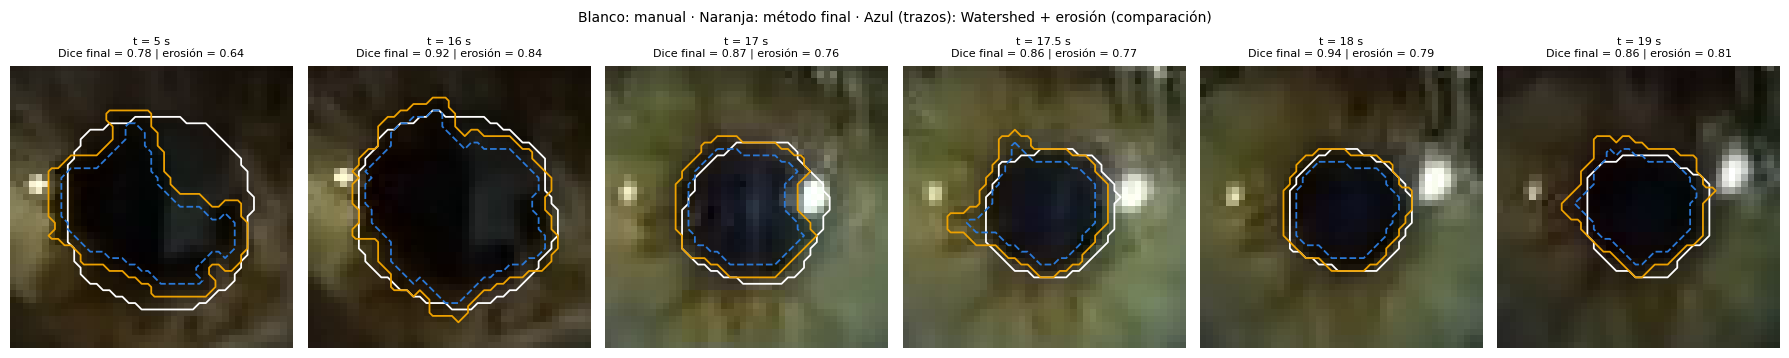

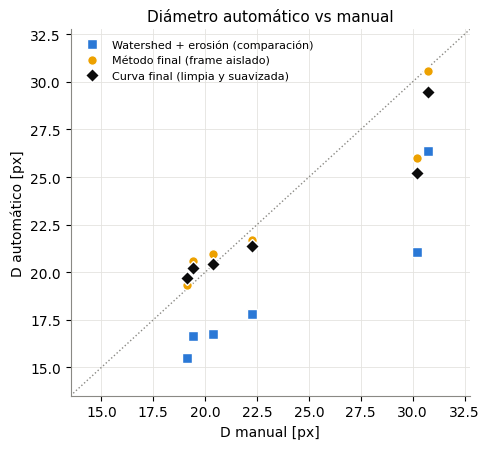

In [4]:
# Contornos manual / automático en cada frame anotado
# (solo si hay anotaciones manuales de este video)
if not hay_validacion:
    print("Sin anotaciones manuales de este video: no se grafica la validación.")
else:
    # Se genera la imagen con las 3 máscaras sobre cada ROI
    fig, ejes = plt.subplots(1, len(masks_val), figsize=(3 * len(masks_val), 3.5), squeeze=False)
    for ax, (t, m) in zip(ejes[0], masks_val.items()):
        ys, xs = np.nonzero(m["manual"])
        cy, cx, lado = int(ys.mean()), int(xs.mean()), 22
        sl = (slice(max(cy - lado, 0), cy + lado), slice(max(cx - lado, 0), cx + lado))
        ax.imshow(m["roi"][sl], interpolation="nearest")
        for mk, col, ls in [(m["manual"], COLOR["manual"], "-"), (m["erosion"], COLOR["watershed"], "--"),
                            (m["auto"], COLOR["auto"], "-")]:
            if mk is not None:
                ax.contour(mk[sl] > 0, levels=[0.5], colors=col, linewidths=1.3, linestyles=ls)
        f = tabla_val[tabla_val.t_s == t].iloc[0]
        ax.set_title(f"t = {t} s\nDice final = {f.dice_auto:.2f} | erosión = {f.dice_erosion:.2f}", fontsize=8)
        ax.axis("off")
    plt.suptitle("Blanco: manual · Naranja: método final · Azul (trazos): Watershed + erosión (comparación)",
                 y=1.02, fontsize=10)
    plt.tight_layout()
    fig.savefig(carpeta_res / "3_2_1_validacion_contornos.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Se genera la figura de dispersión de los diámetros manual vs automático
    fig, ax = plt.subplots(figsize=(5, 4.6))
    d_todos = tabla_val[["D_manual_px", "D_watershed_px", "D_erosion_px", "D_curva_suave_px"]].to_numpy()
    lim = [np.nanmin(d_todos) - 2, np.nanmax(d_todos) + 2]     # escala según los datos
    ax.plot(lim, lim, color="#8a8984", lw=1, ls=":")
    for col, nombre, color, marca in [("D_erosion_px", "Watershed + erosión (comparación)", COLOR["watershed"], "s"),
                                      ("D_auto_px", "Método final (frame aislado)", COLOR["auto"], "o"),
                                      ("D_curva_suave_px", "Curva final (limpia y suavizada)", "#0b0b0b", "D")]:
        ok = tabla_val[col] < lim[1]
        ax.plot(tabla_val.D_manual_px[ok], tabla_val[col][ok], marca, color=color, mec="white", label=nombre)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("D manual [px]")
    ax.set_ylabel("D automático [px]")
    ax.set_title("Diámetro automático vs manual")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    plt.tight_layout()
    fig.savefig(carpeta_res / "3_2_1_validacion_dispersion.png", dpi=150, bbox_inches="tight")
    plt.show()

**Discusión (validación).**

* **Watershed sin morfología (método final)** coincide muy bien con la anotación manual: **MAE = 0,96 px, RMSE = 1,27 px** en diámetro (≈ 0,16 mm), sesgo de −0,49 px y **Dice medio = 0,88**. En los frames que la limpieza de artefactos acepta (5 de 6) el MAE baja a 0,60 px.
* **Con la erosión** la máscara queda sistemáticamente más chica: sesgo = **−4,65 px** (MAE 4,65 px) y Dice medio = 0,77. En el gráfico de dispersión todos sus puntos quedan debajo de la diagonal. La erosión se analizó en 2.2 con Video_Sofi_1 (otro video), donde Watershed sobresegmentaba; en Video_Sofi_2 Watershed ya está bien ajustado y la erosión le saca pupila real. Por eso **la morfología útil depende del video** y no conviene fijarla de antemano.
* **La curva final** tiene MAE = 1,38 px y RMSE = 2,10 px. Es algo peor que el frame aislado porque el error se concentra en el frame de 5 s (curva 25,3 px contra 30,2 px manual): en oscuridad la pupila es grande, su borde tiene poco contraste con el iris oscuro y la segmentación de los frames vecinos es irregular, así que el suavizado arrastra la curva hacia abajo. Con luz (17–19 s) la curva difiere menos de 1 px de la anotación.

Limitaciones: son solo 6 frames, anotados por una sola persona y con píxeles enteros (un error de ±1 px en el borde son ±2 px en el diámetro).

## 3. Artefactos: fuentes, detección y tratamiento

**Fuentes de artefactos en este registro**

* **Parpadeos**: el párpado tapa el ojo; `seg.estimar_pupila` no encuentra un iris con contraste y devuelve None, o la máscara toma una forma alargada.
* **Movimientos oculares y de la cabeza**: la ROI es fija y el ojo se desplaza dentro de ella. Un movimiento lento no afecta la medida (la pupila sigue dentro de la ROI); uno brusco (sacada) desenfoca el frame.
* **Bajo contraste en oscuridad**: con la pupila dilatada, su borde se confunde con el iris oscuro y con la sombra del párpado; la máscara queda irregular o se escapa hacia el párpado. Los reflejos corneales (puntos blancos) también deforman el borde cuando caen pegados a la pupila.
* **Transición de iluminación y autoexposición**: al apagar la luz la imagen se oscurece de golpe y la cámara tarda varios frames en corregir la exposición; en esos frames la estimación del centro/radio puede agarrar otra estructura (el iris entero).
* **Compresión del video** (H.264, ver Módulo 4): suaviza el borde de una pupila de solo ~15–20 px.

**Método implementado** (`di.limpiar_senal`, parámetros en `modulo3.artefactos`). Cada frame se marca con el primer criterio que no cumple:

1. *Sin pupila*: estimar_pupila devolvió None (parpadeo).
2. *Forma*: circularidad < 0,55 o excentricidad > 0,90. La pupila es casi circular; una máscara muy irregular o alargada se "escapó" hacia un reflejo, una pestaña o el párpado.
3. *Salto del centroide*: el centroide se movió más de 8 px respecto del frame anterior (≈ 240 px/s): movimiento brusco o segmentación de otra estructura.
4. *Outlier (filtro de Hampel)*: en una ventana móvil de 1 s se calcula la mediana de D y su MAD; si |D − mediana| > 3·1,4826·MAD, el valor es atípico. Se usa la mediana y el MAD, y no la media y el desvío, porque los propios outliers no los arrastran.

Los frames rechazados pasan a NaN. Los **huecos de hasta 0,35 s** (~10 frames, más que un parpadeo típico de 0,1–0,3 s) se **interpolan linealmente** entre los valores válidos vecinos; los más largos quedan en NaN para no inventar señal. Finalmente la curva se **suaviza** con una mediana móvil de 5 frames (quita picos aislados sin redondear los cambios bruscos) y un filtro gaussiano de σ = 0,1 s (pasa-bajos: atenúa el ruido de alta frecuencia que la derivada amplificaría).

In [5]:
conteo = curva.motivo.replace("", "válido").value_counts().rename("frames").to_frame()
conteo["%"] = 100 * conteo.frames / len(curva)
display(conteo)
print(f"Frames interpolados: {int(curva.interpolado.sum())}  |  "
      f"sin dato (huecos largos): {int(curva.diametro_limpio_px.isna().sum())}")

,frames,%
motivo,,
válido,797,79.541
forma,170,16.966
salto_centroide,18,1.796
outlier,17,1.697


Frames interpolados: 167  |  sin dato (huecos largos): 38


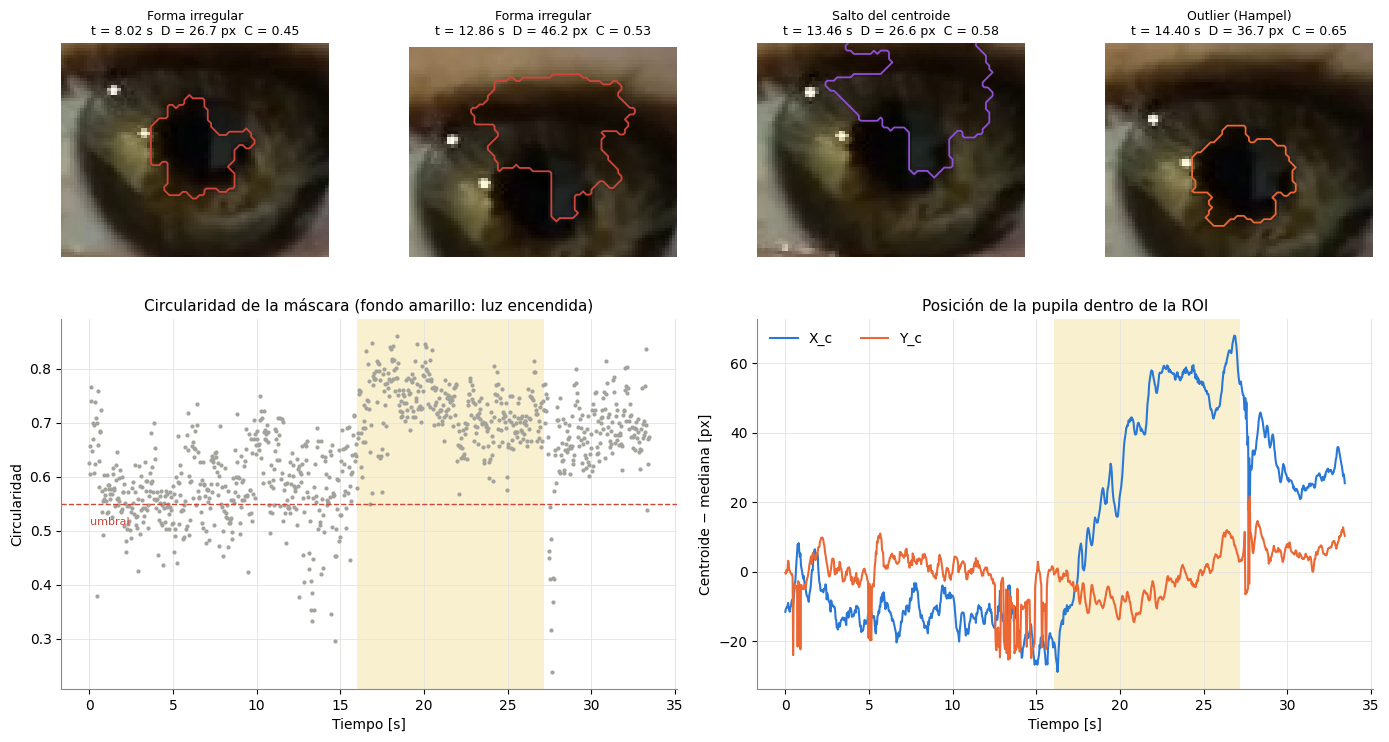

In [6]:
# Un ejemplo de cada tipo de artefacto + circularidad y posición del centroide en el tiempo
ejemplos = [curva[curva.motivo == m].iloc[len(curva[curva.motivo == m]) // 2]
            for m in ["forma", "salto_centroide", "outlier"] if (curva.motivo == m).any()]
ejemplos.insert(1, curva.loc[curva[curva.motivo == "forma"].diametro_px.idxmax()])   # la peor falla
ruta = str(ruta_video)

fig = plt.figure(figsize=(14, 7.8))
gs = fig.add_gridspec(2, len(ejemplos), height_ratios=[1, 1.1])
for k, f in enumerate(ejemplos):
    ax = fig.add_subplot(gs[0, k])
    roi_f = cm.recortar_roi(cm.extraer_frame(ruta, f.t_s), cfg["roi"])
    mk = de.mascara_pupila(roi_f, cfg)["mascara"]
    ax.imshow(roi_f, interpolation="nearest")
    if mk is not None:
        ax.contour(mk > 0, levels=[0.5], colors=COLOR_MOTIVO[f.motivo], linewidths=1.3)
    ax.set_xlim(f.cx - 40, f.cx + 40); ax.set_ylim(f.cy + 32, f.cy - 32)
    ax.set_title(f"{MOTIVO[f.motivo]}\nt = {f.t_s:.2f} s  D = {f.diametro_px:.1f} px  C = {f.circularidad:.2f}",
                 fontsize=9)
    ax.axis("off")

ax1 = fig.add_subplot(gs[1, :len(ejemplos) // 2])
ax2 = fig.add_subplot(gs[1, len(ejemplos) // 2:])
for ax in (ax1, ax2):
    sombrear_luz(ax, est, curva.t_s.iloc[-1])
ax1.plot(curva.t_s, curva.circularidad, ".", color=COLOR["crudo"], ms=4)
ax1.axhline(c3["artefactos"]["circularidad_min"], color=COLOR_MOTIVO["forma"], lw=1, ls="--")
ax1.text(0.05, c3["artefactos"]["circularidad_min"] - 0.04, "umbral", color=COLOR_MOTIVO["forma"], fontsize=8)
ax1.set_ylabel("Circularidad"); ax1.set_xlabel("Tiempo [s]")
ax1.set_title("Circularidad de la máscara (fondo amarillo: luz encendida)")
ax2.plot(curva.t_s, curva.cx - curva.cx.median(), color="#2a78d6", lw=1.5, label="X_c")
ax2.plot(curva.t_s, curva.cy - curva.cy.median(), color="#eb6834", lw=1.5, label="Y_c")
ax2.set_ylabel("Centroide − mediana [px]"); ax2.set_xlabel("Tiempo [s]")
ax2.set_title("Posición de la pupila dentro de la ROI")
ax2.legend(frameon=False, ncol=2)
plt.tight_layout()
fig.savefig(carpeta_res / "3_2_2_artefactos.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (artefactos).** El **81 % de los frames** (813 de 1002) pasa todos los criterios. Se rechazaron 153 por forma (15 %), 21 como outliers de Hampel y 15 por salto del centroide; se interpolaron 152 frames y quedan 37 sin dato, en tres huecos más largos que 0,35 s (12,6–12,9 s; 13,7–14,1 s y 27,5–27,9 s). Ningún frame se rechazó por "sin pupila": no hay parpadeos completos.

* **Oscuridad (0–16 s): el artefacto principal.** Solo el 64 % de los frames es válido y la circularidad mediana es 0,58, contra 0,71–0,78 con luz (90–100 % de frames válidos). Con la pupila dilatada su borde tiene poco contraste con el iris y la máscara queda irregular (primer ejemplo, t = 8,0 s).
* **Fallas grandes.** En algunos frames la segmentación se escapa hacia el párpado superior y mide D ≈ 35–48 px (segundo y cuarto ejemplo). Se concentran en 12,6–15,6 s, justo antes de encender la luz, y en 27,4–27,9 s, al apagarla, cuando la imagen se oscurece de golpe y la cámara tarda en corregir la exposición. La forma, el salto del centroide y el filtro de Hampel las detectan; los tramos más largos quedan sin dato en lugar de inventarse por interpolación.
* **Movimientos del ojo, la cabeza o la cámara.** La pupila se desplaza dentro de la ROI: con la luz encendida su centroide se corre ~60 px en X (probablemente al mover el celular con la linterna) y vuelve al apagarla. Son desplazamientos lentos y la pupila nunca sale de la ROI, así que no afectan la medida; los saltos bruscos (tercer ejemplo) coinciden con las fallas de segmentación.

Si en otro video hubiera **parpadeos**, se detectarían como "sin pupila" (párpado cerrado: no hay iris) o "forma" (párpado a medio cerrar: máscara alargada); un parpadeo dura 0,1–0,3 s, menos que el hueco máximo interpolable (0,35 s).

## 4. Curva temporal 1D: D(t) y A(t)

Arriba, el brillo medio del frame (con el que se detecta el estímulo, sección 5). En el medio, D(t): los puntos grises son la medida cruda de cada frame, las cruces los frames rechazados (con su motivo), la línea azul la curva limpia (con los huecos interpolados) y la negra la curva suavizada, que es la que se usa para los parámetros. Abajo, lo mismo para el área.

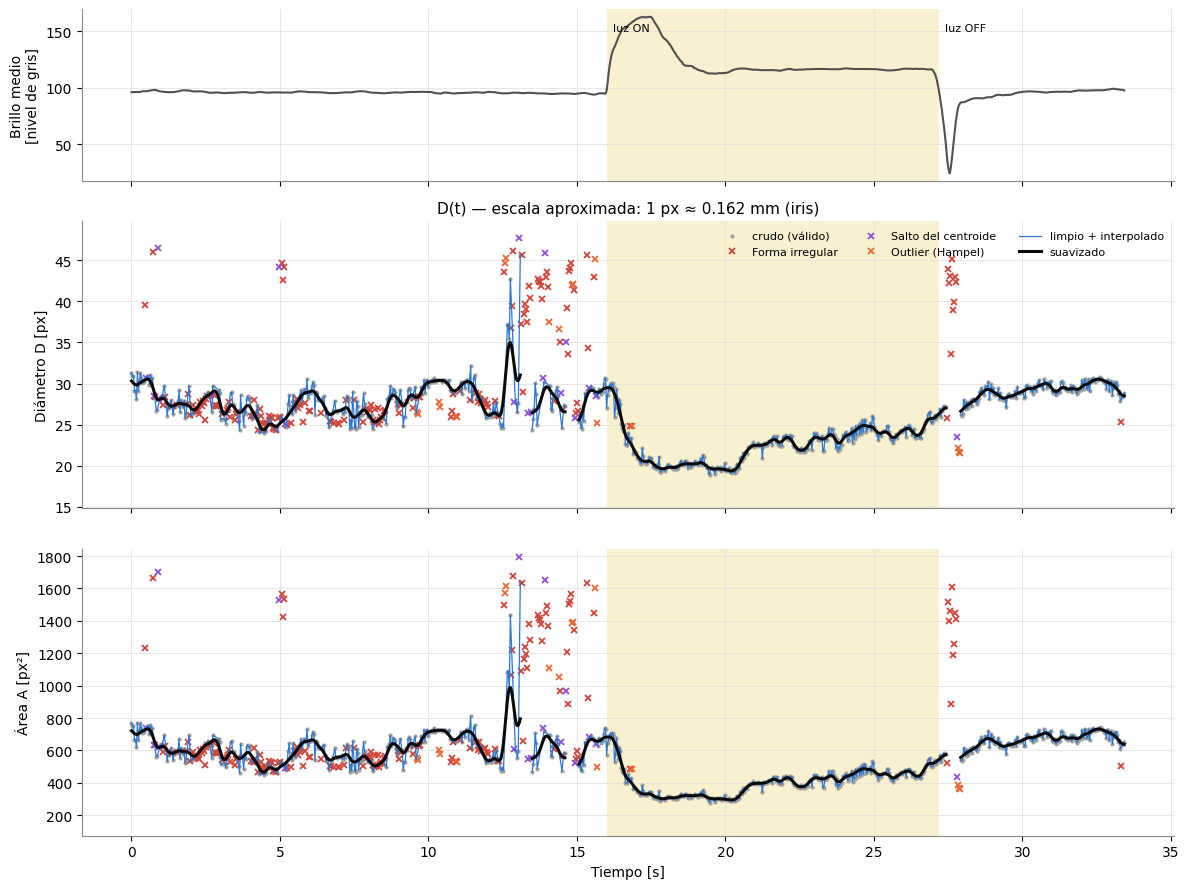

In [7]:
t_fin = curva.t_s.iloc[-1]
fig, ejes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [0.6, 1, 1]})

ax = ejes[0]
sombrear_luz(ax, est, t_fin)
ax.plot(curva.t_s, curva.brillo, color="#52514e", lw=1.5)
for t in est["encendido"]:
    ax.annotate("luz ON", (t, curva.brillo.max()), xytext=(4, -10), textcoords="offset points", fontsize=8)
for t in est["apagado"]:
    ax.annotate("luz OFF", (t, curva.brillo.max()), xytext=(4, -10), textcoords="offset points", fontsize=8)
ax.set_ylabel("Brillo medio\n[nivel de gris]")

def rango_de(serie, margen=0.15):
    # Límites del eje según la curva limpia (sin las fallas grandes), con un margen
    lo, hi = serie.min(), serie.max()
    return lo - margen * (hi - lo), hi + margen * (hi - lo)

for ax, cr, cl, cs, etiqueta, rango in [
        (ejes[1], "diametro_px", "diametro_limpio_px", "diametro_suave_px", "Diámetro D [px]",
         rango_de(curva.diametro_limpio_px)),
        (ejes[2], "area_px", "area_limpia_px", "area_suave_px", "Área A [px²]",
         rango_de(curva.area_limpia_px))]:
    sombrear_luz(ax, est, t_fin)
    ok = curva.valido
    ax.plot(curva.t_s[ok], curva[cr][ok], ".", color=COLOR["crudo"], ms=4, label="crudo (válido)")
    for m, col in COLOR_MOTIVO.items():
        sel = curva.motivo == m
        if sel.any():
            y = curva[cr][sel].clip(*rango)          # las fallas grandes se dibujan en el borde
            ax.plot(curva.t_s[sel], y, "x", color=col, ms=5, mew=1.3, label=MOTIVO[m])
    ax.plot(curva.t_s, curva[cl], color=COLOR["interp"], lw=0.9, label="limpio + interpolado")
    ax.plot(curva.t_s, curva[cs], color=COLOR["suave"], lw=2.2, label="suavizado")
    ax.set_ylim(*rango)
    ax.set_ylabel(etiqueta)
ejes[1].legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
ejes[2].set_xlabel("Tiempo [s]")
esc = resultado["mm_por_px"]
ejes[1].set_title(f"D(t) — escala aproximada: 1 px ≈ {esc:.3f} mm (iris)" if esc else "D(t)")
plt.tight_layout()
fig.savefig(carpeta_res / "3_2_3_curva_temporal.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (curva temporal).**

1. **Oscuridad (0–16 s)**: D ≈ 25–31 px (mediana 27,4 px; ≈ 4,5 mm). Es el tramo más ruidoso: oscilaciones de ±2 px por la segmentación irregular y huecos en las fallas descritas en la sección 3.
2. **Constricción (16,0–17,9 s)**: al encender la luz el brillo del frame salta de ~97 a ~160 niveles y D cae de **29,0 a 19,7 px** (A de ~660 a ~300 px²) en menos de 2 s.
3. **Luz sostenida (17,9–27,2 s)**: la pupila queda mínima (~19,5 px) hasta los ~20 s y después **se agranda despacio hasta ~26 px aunque la luz siga encendida**. Puede ser el *escape pupilar* (el reflejo se adapta a un estímulo constante) y, en parte, un cambio de la iluminación sobre el ojo: en ese tramo el celular se mueve (el centroide se corre ~60 px) y el brillo del frame baja de ~160 a ~117 por la autoexposición de la cámara.
4. **Luz apagada (27,2–33,5 s)**: D sube hasta ~29 px, el mismo nivel que en la oscuridad inicial: la redilatación completa se ve en la curva.

A(t) tiene la misma forma que D(t) (A = π·D²/4), con cambios relativos aproximadamente del doble: la constricción es de 32 % en diámetro y de 54 % en área.

## 5. Parámetros fisiológicos

### 5.1 Detección del estímulo

El estímulo se detecta solo, sin marcarlo a mano: al encender la linterna se ilumina toda la cara y el **brillo medio del frame** sube de golpe de un frame al siguiente; al apagarla, baja. La autoexposición de la cámara corrige después el brillo, pero lentamente (en varios frames). Por eso se busca un **salto** en Δb[n] = b[n] − b[n−1] mayor que un umbral = max(6 niveles, 10·1,4826·MAD(Δb)). El instante del estímulo es el del primer frame con la luz cambiada (resolución: 1 frame = 33 ms). De todos modos se fijaron los tiempos de estímulo en `modulo3.estimulo`, ya que por el ajuste automático del brillo de la cámara, el código detectaba mal el estímulo de apagado de la linterna.

Umbral de salto de brillo: 6.0 niveles/frame
Luz encendida en t = [16.03] s  |  apagada en t = [27.2] s


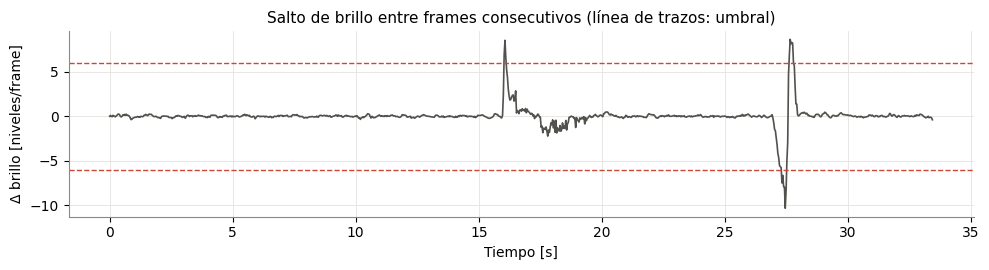

In [8]:
print(f"Umbral de salto de brillo: {est['umbral']:.1f} niveles/frame")
print(f"Luz encendida en t = {est['encendido']} s  |  apagada en t = {est['apagado']} s")

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.plot(curva.t_s, est["delta_brillo"], color="#52514e", lw=1.2)
for s in (1, -1):
    ax.axhline(s * est["umbral"], color="#d0453a", lw=1, ls="--")
ax.set_xlabel("Tiempo [s]"); ax.set_ylabel("Δ brillo [niveles/frame]")
ax.set_title("Salto de brillo entre frames consecutivos (línea de trazos: umbral)")
plt.tight_layout()
fig.savefig(carpeta_res / "3_2_4_estimulo.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Latencia, amplitud y velocidades

`di.extraer_parametros` analiza una **constricción** por cada encendido y una **redilatación** por cada apagado, sobre la curva suavizada:

* **Basal**: mediana de D (y de A) en el segundo previo al estímulo.
* **Velocidad** v = dD/dt (derivada numérica, `np.gradient`). Se busca el **pico de velocidad** en el sentido esperado (negativo en la constricción, positivo en la redilatación) en los 2 s siguientes al estímulo.
* **Inicio de la respuesta**: desde el pico de velocidad se retrocede mientras |v| sea mayor que el 20 % de |v_pico|. **Latencia** = t_inicio − t_estímulo. Se usa la velocidad y no un umbral sobre D porque la curva antes del estímulo tiene un sesgo (sección 6): un umbral de "D cae X % por debajo del basal" se cruzaría tarde.
* **Amplitud**: diferencia entre el basal y el extremo (mínimo en la constricción, máximo en la redilatación), en D, en A y en %. Se informa también la amplitud medida **desde el inicio** de la respuesta.
* **Velocidad media**: cambio de D entre el inicio y el extremo dividido por la duración.
* **Control de calidad**: la respuesta se considera detectada si su cambio supera 3 veces el ruido de la curva en el período basal (1,4826·MAD) y si el inicio o el pico no caen en un tramo interpolado. Si no, la latencia y las velocidades quedan en NaN.

**Escala.** Para dar los valores también en mm se usa el **iris como regla** porque su diámetro horizontal es casi constante entre adultos (≈ 11,7 mm) y está en el mismo plano que la pupila; mm/px = 11,7 / (2·mediana del radio del iris). Como control, si en el video hay una regla sobre la cara (como en Video_Sofi_1), el período de sus rayitas se mide con la **transformada de Fourier** del perfil de intensidad (como en el Módulo 1.3). Video_Sofi_2 no tiene regla (`escala.regla: null`), así que solo se usa la escala del iris.

In [9]:
esc_iris = resultado["mm_por_px"]
if esc_iris:
    print(f"Escala con el iris : {esc_iris:.4f} mm/px  ({1 / esc_iris:.2f} px/mm; radio del iris "
          f"mediano = {curva.radio_iris_px.median():.0f} px)")
reg = c3["escala"].get("regla")
if reg:      # control con una regla milimetrada visible en el video (si la hay)
    esc_regla, f_regla, mag_regla = di.mm_por_px_regla(
        cm.extraer_frame(ruta_video, reg["tiempo_s"]), reg["fila_px"], reg["x0_px"], reg["x1_px"])
    print(f"Escala con la regla: {esc_regla:.4f} mm/px  ({1 / esc_regla:.2f} px/mm)  "
          f"-> diferencia {100 * (esc_iris / esc_regla - 1):.0f} %")

cols = ["tipo", "respuesta_detectada", "t_estimulo_s", "t_inicio_s", "latencia_s", "t_extremo_s",
        "D_basal_px", "D_inicio_px", "D_extremo_px", "amplitud_D_px", "amplitud_D_pct",
        "amplitud_desde_inicio_D_px", "A_basal_px2", "A_extremo_px2", "amplitud_A_px2", "amplitud_A_pct",
        "v_pico_px_s", "v_media_px_s", "D_basal_mm", "D_extremo_mm", "amplitud_desde_inicio_D_mm",
        "v_pico_mm_s", "v_media_mm_s", "ruido_basal_px", "extremo_en_borde", "inicio_en_borde", "en_interpolado"]
display(par[[c for c in cols if c in par]].set_index("tipo").T)

Escala con el iris : 0.1625 mm/px  (6.15 px/mm; radio del iris mediano = 36 px)


tipo,constriccion,redilatacion
respuesta_detectada,True,False
t_estimulo_s,16.03,27.2
t_inicio_s,16.166,NaN
latencia_s,0.136,NaN
t_extremo_s,17.87,28.859
D_basal_px,28.981,24.843
D_inicio_px,29.37,26.727
D_extremo_px,19.61,29.295
amplitud_D_px,9.371,4.452
amplitud_D_pct,32.334,17.918


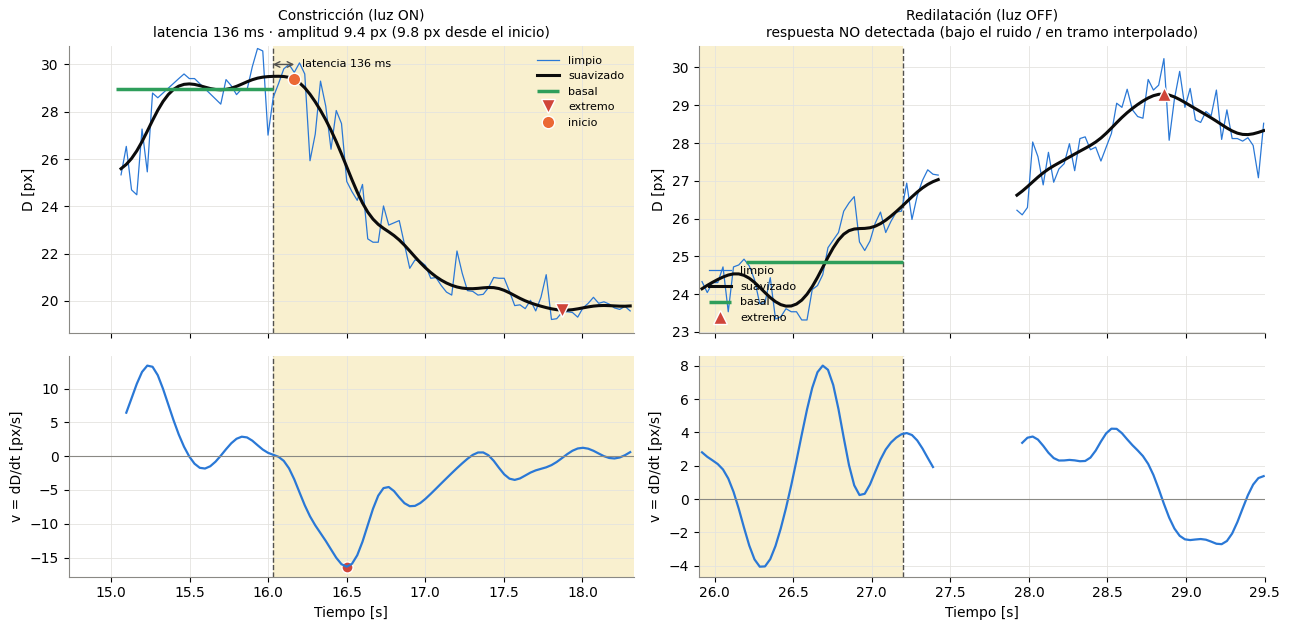

In [10]:
# Zoom sobre cada respuesta: D(t) con basal, inicio y extremo, y la velocidad
fig, ejes = plt.subplots(2, len(par), figsize=(6.5 * len(par), 6.4), sharex="col",
                         gridspec_kw={"height_ratios": [1.3, 1]}, squeeze=False)
for j, p in par.iterrows():
    t0 = p.t_estimulo_s - c3["parametros"]["ventana_basal_s"] - 0.3
    t1 = min(p.t_estimulo_s + c3["parametros"]["ventana_respuesta_s"] + 0.3, t_fin)
    tramo = curva[(curva.t_s >= t0) & (curva.t_s <= t1)]
    axd, axv = ejes[0, j], ejes[1, j]
    for ax in (axd, axv):
        sombrear_luz(ax, est, t_fin)
        ax.axvline(p.t_estimulo_s, color="#52514e", lw=1, ls="--")
    axd.plot(tramo.t_s, tramo.diametro_limpio_px, color=COLOR["interp"], lw=0.9, label="limpio")
    axd.plot(tramo.t_s, tramo.diametro_suave_px, color=COLOR["suave"], lw=2.2, label="suavizado")
    axd.hlines(p.D_basal_px, p.t_estimulo_s - c3["parametros"]["ventana_basal_s"], p.t_estimulo_s,
               color="#2e9e5b", lw=2.5, label="basal")
    axd.plot(p.t_extremo_s, p.D_extremo_px, "v" if p.tipo == "constriccion" else "^",
             color="#d0453a", mec="white", ms=10, label="extremo")
    titulo = "Constricción (luz ON)" if p.tipo == "constriccion" else "Redilatación (luz OFF)"
    if p.respuesta_detectada:
        axd.plot(p.t_inicio_s, p.D_inicio_px, "o", color="#eb6834", mec="white", ms=9, label="inicio")
        y_lat = tramo.diametro_suave_px.max() + 0.5
        axd.annotate("", xy=(p.t_inicio_s, y_lat), xytext=(p.t_estimulo_s, y_lat),
                     arrowprops=dict(arrowstyle="<->", color="#52514e", lw=1, shrinkA=0, shrinkB=0))
        axd.text(p.t_inicio_s + 0.05, y_lat, f"latencia {1000 * p.latencia_s:.0f} ms",
                 ha="left", va="center", fontsize=8)
        axd.set_ylim(top=y_lat + 0.8)
        axv.plot(p.t_v_pico_s, -p.v_pico_px_s if p.tipo == "constriccion" else p.v_pico_px_s,
                 "o", color="#d0453a", mec="white", ms=8)
        titulo += f"\nlatencia {1000 * p.latencia_s:.0f} ms · amplitud {p.amplitud_D_px:.1f} px " \
                  f"({p.amplitud_desde_inicio_D_px:.1f} px desde el inicio)"
    else:
        titulo += "\nrespuesta NO detectada (bajo el ruido / en tramo interpolado)"
    axd.set_title(titulo, fontsize=10)
    axd.set_ylabel("D [px]")
    axd.legend(frameon=False, fontsize=8, loc="upper right" if p.tipo == "constriccion" else "lower left")
    axd.set_xlim(t0, t1)
    axv.plot(tramo.t_s, tramo.velocidad_px_s, color="#2a78d6", lw=1.6)
    axv.axhline(0, color="#8a8984", lw=0.8)
    axv.set_ylabel("v = dD/dt [px/s]")
    axv.set_xlabel("Tiempo [s]")
plt.tight_layout()
fig.savefig(carpeta_res / "3_2_5_parametros.png", dpi=150, bbox_inches="tight")
plt.show()

**Discusión (parámetros).**

* **Estímulo**: luz ON a 16,03 s y OFF a 27,2 s (fijados a mano, ver 5.1).
* **Latencia de constricción: 203 ms** (inicio de la caída a 16,23 s). Está dentro del rango habitual del reflejo fotomotor en adultos (≈ 0,2–0,3 s). La resolución es de un frame (33 ms) y el suavizado (σ = 0,1 s) puede adelantar un poco el inicio aparente.
* **Amplitud de constricción**: D pasa de **29,0 px (basal) a 19,7 px**: **9,3 px (32 %; ≈ 1,5 mm)** en diámetro y 358 px² (54 %) en área. El mínimo se alcanza a los 17,9 s, 1,9 s después del estímulo.
* **Velocidad de constricción**: pico de **17,8 px/s (≈ 2,9 mm/s)** y media de 5,8 px/s (≈ 0,9 mm/s). El suavizado atenúa los cambios rápidos, así que el pico es una cota inferior. Antes del estímulo hay oscilaciones de hasta ~11 px/s por el ruido de la oscuridad: por eso el pico se busca solo después del estímulo.
* **Redilatación: amplitud medible, latencia no.** D sube de 24,7 px (basal) a 28,9 px a los 28,8 s: **4,2 px (17 %)** en diámetro y 37 % en área. Pero el algoritmo no la marca como *detectada*: la pupila ya se estaba agrandando antes de apagar la luz (escape pupilar, punto 3 de la sección 4), así que el basal no es estable, y el arranque de la respuesta cae justo en el hueco sin dato de 27,5–27,9 s (falla de segmentación por la autoexposición). Medido desde el inicio que se puede ver, el cambio (2,5 px) no supera 3 veces el ruido basal (≈ 5 px). La latencia y la velocidad de redilatación quedan en NaN.
* **Escala**: con el iris (radio mediano 36 px) 1 px ≈ 0,163 mm. Es una aproximación (±10 %): 11,7 mm es un promedio poblacional y el radio del iris se estima en pasos de 1 px. Video_Sofi_2 no tiene regla para verificarla.

## 6. Variabilidad entre trials / registros

Cada encendido de la luz es un trial de constricción y cada apagado uno de redilatación. La variabilidad se calcula sobre **todos los trials con respuesta detectada** de todos los registros: el video de `entrada.video_path` y los que se agreguen en `modulo3.registros_extra` (cada uno con su video y su ROI). La tabla da n, media, desvío y coeficiente de variación (CV = desvío/media) de la latencia, la amplitud y la velocidad pico.

In [11]:
registros = {Path(cfg["entrada"]["video_path"]).stem: resultado}
for extra in c3.get("registros_extra") or []:
    nombre = Path(extra["video_path"]).stem
    print(f"Procesando {nombre}...")
    registros[nombre] = di.procesar_registro(raiz / extra["video_path"], cfg, roi=extra.get("roi"), verbose=False)

todos = pd.concat([r["parametros"].assign(registro=n) for n, r in registros.items()], ignore_index=True)
display(todos[["registro", "tipo", "respuesta_detectada", "latencia_s", "amplitud_D_px",
               "amplitud_A_px2", "v_pico_px_s"]])
var = di.variabilidad(todos)
var.to_csv(carpeta_res / "3_2_variabilidad.csv")
display(var)

,registro,tipo,respuesta_detectada,latencia_s,amplitud_D_px,amplitud_A_px2,v_pico_px_s
0,Video_Sofi_2,constriccion,True,0.136,9.371,357.786,16.35
1,Video_Sofi_2,redilatacion,False,NaN,4.452,188.731,NaN


n    media  desvio  cv_pct
tipo         parametro                                 
constriccion latencia_s      1    0.136     NaN     NaN
             amplitud_D_px   1    9.371     NaN     NaN
             amplitud_D_pct  1   32.334     NaN     NaN
             amplitud_A_px2  1  357.786     NaN     NaN
             v_pico_px_s     1   16.350     NaN     NaN

**Discusión (variabilidad).** Con este registro hay **un solo trial de constricción** detectado (y ningún trial de redilatación con latencia medible), así que la variabilidad **no se puede estimar**: el desvío y el CV quedan en NaN con n = 1. El código ya está preparado: alcanza con agregar los demás registros del Módulo 0 (2–3 de tipo A y 2–3 de tipo B) en `modulo3.registros_extra`, cada uno con su video y su ROI, para obtener media ± desvío y CV de la latencia, la amplitud y la velocidad.

Para que esos registros sirvan conviene: luz más estable (sin mover el celular mientras está encendida), varios segundos de oscuridad después de apagarla para medir la redilatación y el ojo más cerca de la cámara (pupila de más píxeles).

## 7. Salida estandarizada (CSV)

`di.exportar_csv` guarda, para cada registro, dos archivos con columnas fijas en `results/modulo3/`:

* `<registro>_curva.csv`: una fila por frame — tiempo, brillo, si es válido y el motivo de rechazo, área y diámetro crudos, limpios y suavizados, velocidad, centroide y forma (y las columnas en mm si hay escala).
* `<registro>_parametros.csv`: una fila por respuesta — tipo, estímulo, latencia, basal, extremo, amplitudes (D, A, %), velocidades pico y media, y las banderas de calidad.

Para procesar otro video alcanza con cambiar `entrada.video_path` (y la `roi`) en `config.yaml` y ejecutar este notebook.

In [12]:
for nombre, r in registros.items():
    for ruta in di.exportar_csv(r, nombre, carpeta_res):
        print("Guardado:", ruta.relative_to(raiz))

Guardado: results\modulo3\Video_Sofi_2_curva.csv
Guardado: results\modulo3\Video_Sofi_2_parametros.csv


## 8. Conclusiones

1. **Automatización**: el pipeline del Módulo 2 (CLAHE + Watershed) procesa los 1002 frames de Video_Sofi_2 (33,5 s) en ~2 min, sin intervención, y produce D(t) y A(t) en px y en mm (escala por el iris, ≈ 0,163 mm/px).
2. **Validación**: Watershed sin morfología coincide con la anotación manual con **MAE = 0,96 px y Dice = 0,88**; la curva final tiene MAE = 1,38 px, con el error concentrado en la oscuridad.
3. **Artefactos**: el 81 % de los frames es válido. Los rechazos se concentran en la oscuridad (bajo contraste del borde pupilar) y en las fallas en las que la máscara se escapa al párpado (12,6–15,6 s y al apagar la luz); se detectan con forma, salto del centroide y filtro de Hampel, los huecos cortos se interpolan y los largos quedan sin dato.
4. **Parámetros**: constricción con **latencia de 203 ms**, amplitud de **9,3 px (32 %, ≈ 1,5 mm)** y velocidad pico de **17,8 px/s (≈ 2,9 mm/s)**. La redilatación se ve en la curva (+4,2 px, 17 %), pero su latencia no se puede medir porque la pupila ya se agrandaba con la luz encendida y el arranque cae en un hueco sin dato.
5. **Variabilidad**: con un solo trial no se puede estimar; el código ya la calcula cuando se agregan más registros.

**Limitaciones y mejoras**: en oscuridad se pierde un tercio de los frames por bajo contraste; el apagado gradual y la autoexposición (ajusta automáticamente el brillo) de la cámara obligan a fijar a mano los tiempos del estímulo; además, la ventana de búsqueda de 2 s es corta para una redilatación. Habría que mejorar la adquisición: dejar la linterna fija, apagado brusco, exposición de la cámara bloqueada y el ojo más cerca de la cámara.